In [ ]:
# PROJETO PDI - CONTAGEM DE PARAFUSOS
# FASE 1 - ORGANIZAÇÃO DO DATASET E GROUND TRUTH

print("FASE 1 - Organização do Dataset e Ground Truth")

import os
import zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from pathlib import Path
from collections import Counter
from google.colab import files

print("Bibliotecas carregadas com sucesso!")

FASE 1 - Organização do Dataset e Ground Truth
Bibliotecas carregadas com sucesso!


In [ ]:
uploaded = files.upload()

arquivo_zip = list(uploaded.keys())[0]

pasta_dataset = Path('/content/dataset_screws')
pasta_dataset.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(arquivo_zip, 'r') as zip_ref:
    zip_ref.extractall(pasta_dataset)

print("Dataset extraído com sucesso!")

Saving screws dataset.v5i.yolov8.zip to screws dataset.v5i.yolov8 (2).zip
Dataset extraído com sucesso!


In [ ]:
extensoes = ['.jpg', '.jpeg', '.png', '.bmp']

imagens = [
    p for p in pasta_dataset.rglob('*')
    if p.is_file() and p.suffix.lower() in extensoes
]

print("Total de imagens encontradas:", len(imagens))

print("\nExemplos de imagens:")

for img in imagens[:5]:
    print(img)

Total de imagens encontradas: 192

Exemplos de imagens:
/content/dataset_screws/test/images/frame_20230530_091814_jpg.rf.8f4af494d17651a1a38a4521ed1f739c.jpg
/content/dataset_screws/test/images/frame_20230622_095305_jpg.rf.527a5d7e72844311e185cef3cdd0d492.jpg
/content/dataset_screws/test/images/frame_20230622_095103_jpg.rf.76203fb999b4b4dbbc40ec3e0ea1d0f0.jpg
/content/dataset_screws/test/images/frame_20230530_092310_jpg.rf.438336b9b229f379396d4f0fad46f0ff.jpg
/content/dataset_screws/test/images/frame_20230622_095419_jpg.rf.ee405b55c3f383f9adc78afd5912dd8a.jpg


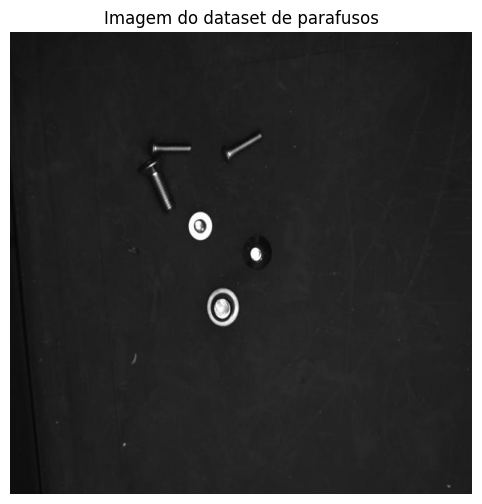

In [ ]:
if not imagens:
    raise ValueError("Nenhuma imagem foi encontrada!")

imagem_teste = cv2.imread(str(imagens[0]))

if imagem_teste is None:
    raise ValueError("Não foi possível carregar a imagem.")

imagem_rgb = cv2.cvtColor(
    imagem_teste,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 6))
plt.imshow(imagem_rgb)
plt.title("Imagem do dataset de parafusos")
plt.axis("off")
plt.show()

In [ ]:
arquivos_yaml = list(pasta_dataset.rglob('data.yaml'))

if not arquivos_yaml:
    raise FileNotFoundError("Arquivo data.yaml não encontrado.")

arquivo_yaml = arquivos_yaml[0]

with open(arquivo_yaml, 'r') as f:
    configuracao = yaml.safe_load(f)

nomes_classes = configuracao['names']

if isinstance(nomes_classes, dict):
    nomes_classes = [
        nomes_classes[i]
        for i in sorted(nomes_classes, key=lambda x: int(x))
    ]

print("Número de classes:", len(nomes_classes))

print("\nClasses encontradas:")

for i, nome in enumerate(nomes_classes):
    print(f"{i} - {nome}")

Número de classes: 5

Classes encontradas:
0 - DST-A1-35
1 - DST-A2-70
2 - N-A2-70
3 - SCM435
4 - YFS-109


In [ ]:
def encontrar_anotacao(imagem):
    partes = list(imagem.parts)

    if 'images' not in partes:
        return None

    indice = partes.index('images')
    partes[indice] = 'labels'

    caminho_label = Path(*partes).with_suffix('.txt')

    if caminho_label.exists():
        return caminho_label

    return None


pares = []

for img in imagens:
    anotacao = encontrar_anotacao(img)

    pares.append({
        'imagem': img,
        'anotacao': anotacao
    })

imagens_sem_anotacao = [
    p['imagem'] for p in pares
    if p['anotacao'] is None
]

print("Total de imagens:", len(imagens))
print("Imagens com anotação:", len(imagens) - len(imagens_sem_anotacao))
print("Imagens sem anotação:", len(imagens_sem_anotacao))

print("\nDistribuição das imagens:")

for conjunto in ['train', 'valid', 'test']:
    quantidade = sum(
        conjunto in img.parts for img in imagens
    )
    print(f"{conjunto}: {quantidade}")

Total de imagens: 192
Imagens com anotação: 192
Imagens sem anotação: 0

Distribuição das imagens:
train: 162
valid: 17
test: 13


In [ ]:
if imagens_sem_anotacao:
    raise ValueError(
        "Existem imagens sem anotação. Corrija antes de continuar."
    )

registros = []
contagem_total_classes = Counter()

for par in pares:

    img = par['imagem']
    arquivo_label = par['anotacao']

    conjunto = next(
        (p for p in img.parts if p in ['train', 'valid', 'test']),
        'desconhecido'
    )

    contagem_classes = {
        nome: 0 for nome in nomes_classes
    }

    with open(arquivo_label, 'r') as f:
        linhas = [
            linha.strip()
            for linha in f
            if linha.strip()
        ]

    for linha in linhas:

        valores = linha.split()

        if len(valores) != 5:
            raise ValueError(
                f"Anotação inválida em: {arquivo_label}"
            )

        classe_id = int(valores[0])

        if classe_id < 0 or classe_id >= len(nomes_classes):
            raise ValueError(
                f"Classe inválida em: {arquivo_label}"
            )

        nome_classe = nomes_classes[classe_id]

        contagem_classes[nome_classe] += 1
        contagem_total_classes[nome_classe] += 1

    registro = {
        'imagem': img.name,
        'conjunto': conjunto
    }

    registro.update(contagem_classes)

    registro['quantidade_real'] = sum(
        contagem_classes.values()
    )

    registros.append(registro)

ground_truth = pd.DataFrame(registros)

ground_truth = ground_truth.sort_values(
    by=['conjunto', 'imagem']
).reset_index(drop=True)

display(ground_truth.head(10))

print("\nTotal de imagens:", len(ground_truth))

print(
    "Total de parafusos:",
    ground_truth['quantidade_real'].sum()
)

print("\nTotal de objetos por classe:")

for classe, quantidade in contagem_total_classes.items():
    print(f"{classe}: {quantidade}")

,imagem,conjunto,DST-A1-35,DST-A2-70,N-A2-70,SCM435,YFS-109,quantidade_real
0,frame_20230530_091814_jpg.rf.8f4af494d17651a1a...,test,2,1,1,0,1,5
1,frame_20230530_092310_jpg.rf.438336b9b229f3793...,test,0,2,0,0,0,2
2,frame_20230615_135703_jpg.rf.b2938501a60400a7e...,test,0,0,1,2,0,3
3,frame_20230620_133947_jpg.rf.f415f2f265ae152cc...,test,0,0,2,2,0,4
4,frame_20230622_095103_jpg.rf.76203fb999b4b4dbb...,test,3,3,3,3,3,15
5,frame_20230622_095214_jpg.rf.b9a37f9856de97c3f...,test,1,2,3,1,3,10
6,frame_20230622_095305_jpg.rf.527a5d7e72844311e...,test,2,1,3,1,3,10
7,frame_20230622_095419_jpg.rf.ee405b55c3f383f9a...,test,1,1,1,1,1,5
8,frame_20230622_095458_jpg.rf.a827ac654fef1ce85...,test,1,1,1,1,1,5
9,frame_20230622_101953_jpg.rf.2aac6c7206a1973dd...,test,0,0,0,2,3,5



Total de imagens: 192
Total de parafusos: 1197

Total de objetos por classe:
DST-A1-35: 259
DST-A2-70: 236
N-A2-70: 235
YFS-109: 247
SCM435: 220


In [ ]:
pasta_resultados = Path('/content/resultados')
pasta_resultados.mkdir(exist_ok=True)

arquivo_csv = pasta_resultados / 'ground_truth.csv'

ground_truth.to_csv(
    arquivo_csv,
    index=False,
    encoding='utf-8-sig'
)

print("Ground Truth salvo com sucesso!")
print(arquivo_csv)

files.download(str(arquivo_csv))

Ground Truth salvo com sucesso!
/content/resultados/ground_truth.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def calcular_metricas(resultados):

    erros = (
        resultados['quantidade_real']
        - resultados['quantidade_detectada']
    )

    mae = erros.abs().mean()

    rmse = np.sqrt((erros ** 2).mean())

    acuracia_exata = (
        resultados['quantidade_real']
        == resultados['quantidade_detectada']
    ).mean() * 100

    return {
        'MAE': mae,
        'RMSE': rmse,
        'Acuracia_exata (%)': acuracia_exata
    }

print("Função de métricas implementada!")

Função de métricas implementada!


# Informações sobre o que foi feito:

*   Escolha e organização do dataset;
* Identificação  dsa classes de objetos presentes;
* Verificação das imagens e suas respectivas anotações;
* Construçao do Ground Truth;
* Preparação dasmétricas que serão utilizadas para avaliar o desempenho do algoritmo.

  O dataset escolhido foi o Screws Dataset, do Roboflow (https://universe.roboflow.com/deviastage/screws-dataset-vqogv/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true), ele possui 5 cçasses de parafusos:

  * DST-A1-35
  * DST-A2-70
  * N-A2-70
  * SCM435
  * YFS-109

  Para as métricas utilizadas temos:

* MAE – Erro Absoluto Médio: mede, em média, quantos parafusos o algoritmo erra na contagem de cada imagem, sem considerar se contou a mais ou a menos;
* RMSE – Raiz do Erro Quadrático Médio: mede o erro de contagem, dando maior peso aos erros mais elevados;
* Acurácia Exata: mede a porcentagem de imagens em que o algoritmo acertou exatamente a quantidade de parafusos.
